In [397]:
import pandas as pd
from statsmodels.stats.inter_rater import fleiss_kappa
import plotly.graph_objects as go
import matplotlib.pyplot as plt

### Data prep

In [398]:
df = pd.read_csv('merged_annotations.csv')

In [399]:
df.head()

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,none,none,none
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,agency,agency,agency
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,none,none,none
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,none,none,none
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,agency,agency,agency


In [400]:
def normalize_annotations(df, columns):
    for col in columns:
        df[col] = df[col].astype(str).str.strip().str.lower()
    return df

In [401]:
df = normalize_annotations(
    df,
    ["label_lisa", "label_julian", "label_thea"]
)

In [402]:
for col in ['label_lisa', 'label_julian', 'label_thea']:
    print(f"{col}: dtype = {df[col].dtype}, unique = {df[col].unique()}")

label_lisa: dtype = object, unique = ['none' 'agency' 'externalization']
label_julian: dtype = object, unique = ['none' 'agency' 'externalization']
label_thea: dtype = object, unique = ['none' 'agency' 'externalization' 'nan']


In [403]:
df["label_thea"] = df["label_thea"].replace("nan", "none")

In [404]:
df['token_count'] = df['text'].apply(lambda x: len(str(x).split()))


In [405]:
min_tokens_per_sentence = df['token_count'].min()
average_tokens_per_sentence = df['token_count'].mean()
max_tokens_per_sentence = df['token_count'].max()

### Rows with least amount of tokens in the text

In [406]:
print(f"Average number of tokens per sentence: {min_tokens_per_sentence}")
print(f"Average number of tokens per sentence: {average_tokens_per_sentence}")
print(f"Average number of tokens per sentence: {max_tokens_per_sentence}")

Average number of tokens per sentence: 1
Average number of tokens per sentence: 20.861774744027304
Average number of tokens per sentence: 182


In [407]:
sorted_df = df.sort_values(by='token_count')


### Rows with least amount of tokens in the text

In [408]:
lowest_token_count_rows = sorted_df.head(7)
lowest_token_count_rows

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,none,none,none,1
435,Yes.,seselj_Public_Transcript_of_Hearing_22_January_2008_564,0,none,none,none,1
301,No.,"krstic_Public_Transcript_of_Hearing_October_19th,_2000_215",0,none,none,none,1
21,227.,prlic_and_others_Public_Transcript_of_Hearing_26_March_2007_159,1,none,none,none,1
130,No.,"vasiljevic_Public_Transcript_of_Hearing_October_26th,_2001_50",0,none,none,none,1
99,Yes.,simic_et_al_Public_Transcript_of_Hearing_8_May_2003_235,0,none,none,none,1
160,Fine.,"milosevic_02-54_Public_Transcript_of_Hearing_January_22nd,_2004_378",0,none,none,none,1


### Rows with most amount of tokens in the text

In [409]:
highest_token_count_rows = sorted_df.tail(7)
highest_token_count_rows

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
413,"But be that as it may, we stayed because we hoped, we believed, we were confident, in spite of the smell of gunpowder and clinking of weapons that it wouldn't last long and that both sides - and when I say sides, I think you understand whom I mean - that they would realise that it would be madness, unnecessary, and that it would be -- that it will come to an end shortly.","krnojelac_Public_Transcript_of_Hearing_June_25th,_2001_214",4,agency,agency,externalization,74
37,"Do you agree that this is my order to the Main Staff of the Army of Republika Srpska, to the Supreme Court-Martial, and the Military Prosecutor's Office dated the 15th of December, 1994 by which I order that there should be co-operation with the Supreme Court-Martial and prosecutor's office of the army in accordance with the law and that instructions be issued to security organs in order to enable the operation of judiciary tasks?",karadzic_and_mladic_95-5_18_Public_Transcript_of_Hearing_dated_30_June_2011_48,0,none,agency,agency,74
171,"I have already said that he had a diametrically contrary view to Mr. Valenta and that he endeavoured, and we saw this in the previous document, that whereas the -- while the conflict existed in Busovaca, the document that you showed me a moment ago, in Vitez a meeting was being held on the creation of a joint government, a Croatian and Bosniak Muslim government, and I know that he did everything in his power to ensure coexistence with the Bosniak Muslims.",blaskic_Public_Transcript_of_Hearing_05_May_1999_367,0,none,none,none,82
146,"And this is why a certain number of Serbs was returned or actually they did not even cross on the other side, and this is what people were saying, the people with whom we were having lunch, they were sitting there, we were talking to them and they knew who they were because they had arrived there with them together on the other bank of the river which was under the control of the HVO and the forces of the municipality of Odzak.",simic_et_al_Public_Transcript_of_Hearing_15_May_2003_73,1,none,externalization,externalization,83
98,"I arrived in the evening, and I was immediately informed in greater detail about events in the Lasva River Valley, which at that time was cut in two; namely, the forces of the army of Bosnia-Herzegovina in the region of Buhine Kuce had under their control the main road, and they also took the positions south of the main road, so that is the period when we were brought into a situation where we had two pockets in the region of Buhine Kuce.",blaskic_Public_Transcript_of_Hearing_08_April_1999_22,0,none,externalization,none,83
432,"Our lines in the area of Gornji Vakuf are in disarray, for all intents and purposes, and I add here that at that time in particular -- with many, but in particular there were problems with the units from Livno, for a very simple reason, because they were under strong influence of their local authorities, and Mr. Stanko Vrgoc and Mr. Andabak sometimes - and we'll see later - to put it quite simply, did not obey orders, and here in the PS, I actually threaten them; although if you were to ask me what I had to threaten them with, I would be hard-pressed to give you an answer.",prlic_and_others_Public_Transcript_of_Hearing_02_June_2009_23,2,agency,externalization,agency,110
145,"I have heard something about it when they arrived at the company Tekstilac, actually this is a restaurant, and there was a welcoming lunch for the representatives of the International Red Cross and these people had arrived on that side to say that way, and I had heard then from the conversation that there were -- there was about ten Serbs who were on the other side in the territory of the municipality of Odzak, they were supposed to cross but they did not, either because it was not allowed for them to do so or I don't know what the truth is, but there was a certain number of Croats and I don't know 

### Fleiss' kappa

In [410]:
mapping = {'none': 0, 'agency': 1, 'externalization': 2}


In [411]:
df['label_julian'] = df['label_julian'].map(mapping)
df['label_thea'] = df['label_thea'].map(mapping)
df['label_lisa'] = df['label_lisa'].map(mapping)

In [412]:
df.head()

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,0,0,0,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,1,1,1,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,0,0,0,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,0,0,0,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,1,1,1,38


In [413]:
# Prepare the data for Fleiss' Kappa calculation
annotations = df[['label_julian', 'label_thea', 'label_lisa']]

In [414]:
annotations.head()

,label_julian,label_thea,label_lisa
0,0,0,0
1,1,1,1
2,0,0,0
3,0,0,0
4,1,1,1


In [415]:
# Initialize a DataFrame with zeros for category counts
category_counts = pd.DataFrame(0, index=annotations.index, columns=[0, 1, 2])

In [416]:

for i, row in annotations.iterrows():
    counts = row.value_counts().reindex(range(3), fill_value=0)
    category_counts.loc[i] = counts

In [417]:
if not all(category_counts.sum(axis=1) == len(annotations.columns)):
    raise ValueError("Mismatch in the number of raters per sentence.")

In [418]:
kappa = fleiss_kappa(category_counts.values)

In [419]:
print(f"Fleiss' Kappa: {kappa}")

Fleiss' Kappa: 0.6089043197893904


### Krippendorff's alpha

In [420]:
!pip install krippendorff

You should consider upgrading via the 'c:\users\krusic\appdata\local\programs\python\python39\python.exe -m pip install --upgrade pip' command.


In [421]:
import pandas as pd
import krippendorff

In [422]:
annotations = df[['label_julian', 'label_thea', 'label_lisa']].transpose().values

In [423]:
alpha = krippendorff.alpha(reliability_data=annotations, level_of_measurement='nominal')


In [424]:
print(f"Krippendorff's Alpha: {alpha}")


Krippendorff's Alpha: 0.6091267860466205


### Krippendorf & Kappa 0.6 (moderate)

### Percent agreement - 98 % two-out-of-three, 70 % 3/3

In [425]:
agreement = (
    (df["label_lisa"] == df["label_julian"]) &
    (df["label_julian"] == df["label_thea"])
)

percent_agreement = agreement.mean() * 100

print(f"Complete agreement: {percent_agreement:.2f}%")

Complete agreement: 70.14%


In [426]:
df

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,0,0,0,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,1,1,1,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,0,0,0,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,0,0,0,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,1,1,1,38
5,The political leadership in Pale never issued such an order.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,5,0,0,0,10
6,They had taken Vogosca before I came from Pale.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,6,2,2,2,9
7,"When I say took it, they actually put their demarcation line where they put it.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,7,2,0,0,15
8,All on their own initiative.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,8,2,2,2,5
9,"But the discussion was, then, whether the Serb negotiating team had sold Vogosca, and I played arbitrator.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,9,1,1,1,17


In [427]:
def calculate_two_out_of_three_agreement_for_all(df):
    # True if at least two of the three annotators agree
    df_with_agreement = df.assign(
        agreement=(
            (df["label_lisa"] == df["label_julian"]) |
            (df["label_julian"] == df["label_thea"]) |
            (df["label_lisa"] == df["label_thea"])
        )
    )

    percent_agreement = df_with_agreement["agreement"].mean() * 100

    return percent_agreement

In [428]:
percent_two_thirds = calculate_two_out_of_three_agreement_for_all(df)

print(f"At least 2/3 agreement: {percent_two_thirds:.2f}%")

At least 2/3 agreement: 98.12%


In [429]:
def find_complete_disagreement(df, ann1, ann2, ann3):
    return df[
        (df[ann1] != df[ann2]) &
        (df[ann2] != df[ann3]) &
        (df[ann1] != df[ann3])
    ]

In [430]:
complete_disagreement = find_complete_disagreement(
    df,
    "label_lisa",
    "label_julian",
    "label_thea"
)

In [431]:
print(type(complete_disagreement))
print(complete_disagreement.shape)
print(complete_disagreement.empty)

<class 'pandas.core.frame.DataFrame'>
(11, 7)
False


### Rows with complete disagreement in annotation (11 rows)

In [432]:
complete_disagreement[
    ["text", "label_lisa", "label_julian", "label_thea"]
]

,text,label_lisa,label_julian,label_thea
43,"I never received any order from the head of the main staff of the Croatian army, nor any instructions, nor any orders from the Ministry of Defence of the Republic of Croatia, nor did I ever send any reports to those institutions.",1,0,2
137,"But I say here, since I was quoted out of context, that the threats reached a climax in violence.",1,2,0
140,And then I go on to say that is how it always was in human society.,1,2,0
150,"I know that for certain, because the ethnic regions, our ethnic regions in the west, remained with the Muslims - Grahovo, Glamoc, Drvar, and so on - whereas we had in our possession in the eastern part along the Drina, important territories, so that's why Mr. Karadzic said that in figurative terms, the Drina is ours, having in mind the contact plan.",2,1,0
151,"Now, as far as this goal is concerned, it's exactly as I stated, why we had planned it that way, not to have Drina the border between these two worlds, and that is something that Mr. Izetbegovic confirmed, and he said this, that there shouldn't be any passports or anything like that.",2,1,0
196,"With your permission, may I say that I never hid anything that I knew, or rather, what I heard from others in terms of what they conveyed to me.",1,0,2
228,"And then I say, All right, that's it.",1,0,2
279,"This order was written following the press conference, and after I became satisfied that the activities which had been committed by the 7th Muslim Brigade, based on the information I had, did represent a classical case of terrorism, and this order still was directed against such terrorist activities.",2,1,0
313,"That is what I am saying now, but in those days, I didn't give the matter much thought.",0,1,2
398,It's possible that I attended some meeting of that kind in that role.,1,0,2


In [433]:
complete_agreement = df[
    (df["label_lisa"] == df["label_julian"]) &
    (df["label_julian"] == df["label_thea"]) &
    (df["label_lisa"] == df["label_thea"])
]

In [434]:
pd.set_option('display.max_colwidth', None)  # Set to None to prevent truncation
pd.set_option('display.max_rows', None)  # Show all columns


### Rows with complete agreement (411 rows)

In [435]:
complete_agreement.head()

,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,0,0,0,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,1,1,1,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,0,0,0,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,0,0,0,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,1,1,1,38


In [436]:
print(f"Nr of rows with complete agreement among annotators: {len(complete_agreement)} ({len(complete_agreement) / len(df):.2%})")


Nr of rows with complete agreement among annotators: 411 (70.14%)


### Distribution of annotations

In [437]:
label_cols = ["label_lisa", "label_julian", "label_thea"]

overall_counts = (
    df[label_cols]
    .stack()
    .value_counts()
    .to_dict()
)

print(overall_counts)

{0: 1118, 2: 401, 1: 239}


In [438]:
annotator_counts = {
    "lisa": df["label_lisa"].value_counts(),
    "julian": df["label_julian"].value_counts(),
    "thea": df["label_thea"].value_counts()
}

annotator_counts

{'lisa': label_lisa
 0    369
 2    124
 1     93
 Name: count, dtype: int64,
 'julian': label_julian
 0    389
 2    122
 1     75
 Name: count, dtype: int64,
 'thea': label_thea
 0    360
 2    155
 1     71
 Name: count, dtype: int64}

In [439]:
print("Overall Counts:", overall_counts)
print("\nCounts Per Annotator:")
for annotator, counts in annotator_counts.items():
    print(f"{annotator.capitalize()} Counts:\n{counts}\n")


Overall Counts: {0: 1118, 2: 401, 1: 239}

Counts Per Annotator:
Lisa Counts:
label_lisa
0    369
2    124
1     93
Name: count, dtype: int64

Julian Counts:
label_julian
0    389
2    122
1     75
Name: count, dtype: int64

Thea Counts:
label_thea
0    360
2    155
1     71
Name: count, dtype: int64



#### Plotting distribution of annotations per annotator

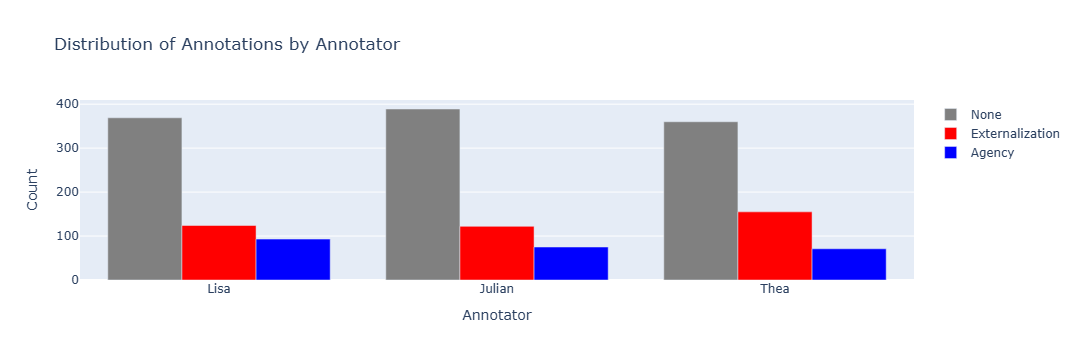

In [440]:
# Numeric annotation categories
annotations = [0, 2, 1]

# Count annotations for each annotator
lisa_counts = (
    df["label_lisa"]
    .value_counts()
    .reindex(annotations, fill_value=0)
)

julian_counts = (
    df["label_julian"]
    .value_counts()
    .reindex(annotations, fill_value=0)
)

thea_counts = (
    df["label_thea"]
    .value_counts()
    .reindex(annotations, fill_value=0)
)

# Colors
colors = {
    0: "grey",   # none
    1: "blue",   # agency
    2: "red"     # externalization
}

fig = go.Figure()

# None (0)
fig.add_trace(go.Bar(
    x=["Lisa", "Julian", "Thea"],
    y=[
        lisa_counts[0],
        julian_counts[0],
        thea_counts[0]
    ],
    name="None",
    marker_color=colors[0]
))

# Externalization (2)
fig.add_trace(go.Bar(
    x=["Lisa", "Julian", "Thea"],
    y=[
        lisa_counts[2],
        julian_counts[2],
        thea_counts[2]
    ],
    name="Externalization",
    marker_color=colors[2]
))

# Agency (1)
fig.add_trace(go.Bar(
    x=["Lisa", "Julian", "Thea"],
    y=[
        lisa_counts[1],
        julian_counts[1],
        thea_counts[1]
    ],
    name="Agency",
    marker_color=colors[1]
))

fig.update_layout(
    title="Distribution of Annotations by Annotator",
    xaxis_title="Annotator",
    yaxis_title="Count",
    barmode="group"
)

fig.show()

In [441]:
def get_two_thirds_agreement(df):
    mask = df.apply(
        lambda row: len(set([
            row["label_lisa"],
            row["label_julian"],
            row["label_thea"]
        ])) < 3,
        axis=1
    )

    return df[mask].copy()


two_thirds_agreement = get_two_thirds_agreement(df)

In [442]:
print(f"Rows with at least 2/3 agreement: {len(two_thirds_agreement)}")

two_thirds_agreement.head()

Rows with at least 2/3 agreement: 575


,text,unique_id,sentence_index,label_lisa,label_julian,label_thea,token_count
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,0,0,0,1
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,1,1,1,55
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,0,0,0,19
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,0,0,0,7
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,1,1,1,38


### 575 rows with 2/3 agreement

In [443]:
def create_majority_df(df):
    label_cols = [
        "label_lisa",
        "label_julian",
        "label_thea"
    ]

    def majority_annotation(row):
        annotations = row[label_cols].tolist()

        for annotation in annotations:
            if annotations.count(annotation) >= 2:
                return annotation

        return None  # no majority

    majority_df = df.copy()

    # Create majority label
    majority_df["label"] = majority_df.apply(
        majority_annotation,
        axis=1
    )

    # Remove rows without majority agreement
    majority_df = majority_df.dropna(subset=["label"])

    # Convert label back to integer
    majority_df["label"] = majority_df["label"].astype(int)

    # Remove individual annotator columns
    majority_df = majority_df.drop(columns=label_cols)

    return majority_df

In [444]:
majority_df = create_majority_df(df)

In [445]:
majority_df

,text,unique_id,sentence_index,token_count,label
0,No.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,0,1,0
1,"I don't know what this man wrote here but I can tell you that there was a quarrel among the leaders in Vogosca and I came to arbitrate, to help them reach an understanding, and the subject of discussion was Vogosca was sold and I said Vogosca was important to us because of its industry.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,1,55,1
2,"And the man here says that the political leadership had ordered Vogosca to be taken, which is not true.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,2,19,0
3,It was just divided into two halves.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,3,7,0
4,"I remember there was a quarrel and I said to them, clearly, Vogosca has not been sold, so I came to tell them what really happened at the negotiations, that there was a quarrel among the political leadership.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,4,38,1
5,The political leadership in Pale never issued such an order.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,5,10,0
6,They had taken Vogosca before I came from Pale.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,6,9,2
7,"When I say took it, they actually put their demarcation line where they put it.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,7,15,0
8,All on their own initiative.,krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,8,5,2
9,"But the discussion was, then, whether the Serb negotiating team had sold Vogosca, and I played arbitrator.",krajisnik_Public_Transcript_of_Hearing_09_June_2006_157,9,17,1


In [446]:
majority_df["label"].unique()

array([0, 1, 2])

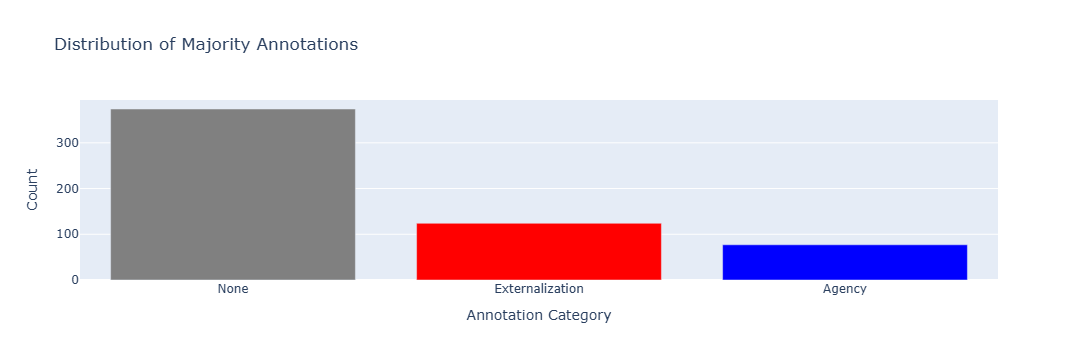

In [447]:
# 0 = none
# 1 = agency
# 2 = externalization

# Count annotations in desired display order
annotation_counts = (
    majority_df["label"]
    .value_counts()
    .reindex(
        [0, 2, 1],
        fill_value=0
    )
)

colors = {
    0: "grey",   # none
    1: "blue",   # agency
    2: "red"     # externalization
}

fig = go.Figure()

fig.add_trace(go.Bar(
    x=["None", "Externalization", "Agency"],
    y=annotation_counts.values,
    marker_color=[
        colors[0],
        colors[2],
        colors[1]
    ]
))

fig.update_layout(
    title="Distribution of Majority Annotations",
    xaxis_title="Annotation Category",
    yaxis_title="Count"
)

fig.show()

In [448]:
annotation_counts = majority_df['label'].value_counts()
annotation_counts

label
0    374
2    124
1     77
Name: count, dtype: int64

In [449]:
grouped = majority_df.groupby('label')['token_count'].agg(['mean', 'median', 'std', 'count'])

# Display the descriptive statistics
print(grouped)



            mean  median        std  count
label                                     
0      17.772727    15.0  13.443326    374
1      29.558442    26.0  18.655812     77
2      23.967742    19.0  20.740728    124


In [450]:
majority_df.to_csv('ground_truth.csv')